In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("/content/Housing.csv")

# Display first five rows
print("First Five Rows:")
display(df.head())

# Display dataset shape
print("\nDataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types
print("\nData Types:")
print(df.dtypes)

First Five Rows:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Dataset Shape: (545, 13)

Column Names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Data Types:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


In [5]:
# Statistical summary
print("Statistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Dataset information
print("\nDataset Information:")
df.info()

Statistical Summary:


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000



Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate Records: 0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 no

In [6]:
# Remove duplicate records
df = df.drop_duplicates()

# Convert area and price into numeric values
df['area'] = pd.to_numeric(df['area'], errors='coerce')
df['price'] = pd.to_numeric(df['price'], errors='coerce')

# Remove rows with missing or invalid price
df = df.dropna(subset=['price'])

# Remove non-positive prices and areas
df = df[df['price'] > 0]
df.loc[df['area'] <= 0, 'area'] = np.nan

# Fill missing area values using median
df['area'] = df['area'].fillna(df['area'].median())

print("Dataset after cleaning:")
display(df.head())

print("\nFinal Dataset Shape:", df.shape)
print("\nMissing Values After Cleaning:")
print(df[['area', 'price']].isnull().sum())

Dataset after cleaning:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420.0,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960.0,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960.0,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500.0,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420.0,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Final Dataset Shape: (545, 13)

Missing Values After Cleaning:
area     0
price    0
dtype: int64


In [7]:
# Independent variable
X = df[['area']]

# Dependent variable
y = df['price']

print("Input Feature: Area")
print("Target Variable: Price")

print("\nInput Feature Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Feature: Area
Target Variable: Price

Input Feature Shape: (545, 1)
Target Variable Shape: (545,)


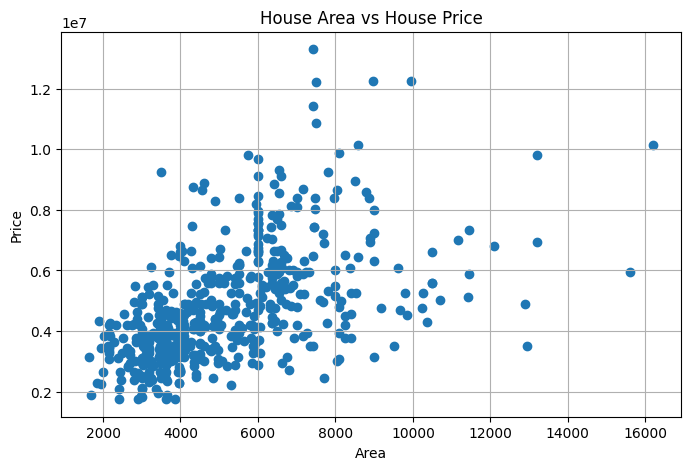

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(df['area'], df['price'])

plt.title('House Area vs House Price')
plt.xlabel('Area')
plt.ylabel('Price')

plt.grid(True)
plt.show()

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape[0])
print("Testing Data:", X_test.shape[0])

Training Data: 436
Testing Data: 109


In [10]:
# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Display coefficient and intercept
print("Coefficient (Slope):", model.coef_[0])
print("Intercept:", model.intercept_)

print("\nLinear Regression Equation:")
print(f"Price = {model.intercept_:.2f} + ({model.coef_[0]:.2f} * Area)")

Coefficient (Slope): 425.72984193878284
Intercept: 2512254.2639593435

Linear Regression Equation:
Price = 2512254.26 + (425.73 * Area)


In [11]:
# Predict prices using testing data
y_pred = model.predict(X_test)

# Display actual and predicted prices
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print("Actual vs Predicted House Prices:")
display(comparison.head(10))

Actual vs Predicted House Prices:


,Actual Price,Predicted Price
0,4060000,5.024060e+06
1,6650000,5.279498e+06
2,3710000,4.232203e+06
3,6440000,4.640903e+06
4,2800000,4.198144e+06
5,4900000,5.373159e+06
6,5250000,6.139473e+06
7,4543000,4.636646e+06
8,2450000,3.891619e+06
9,3353000,3.661725e+06


In [12]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 1474748.1337969352
Mean Squared Error (MSE): 3675286604768.185
Root Mean Squared Error (RMSE): 1917103.7021424233
R2 Score: 0.27287851871974644


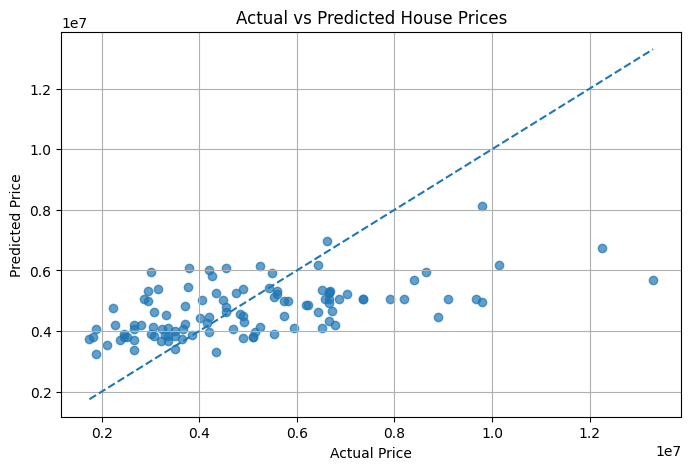

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction reference line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')

plt.grid(True)
plt.show()

In [14]:
# Select a new house area within the dataset's observed range
new_area = float(df['area'].median())

# Predict house price
new_house = pd.DataFrame({'area': [new_area]})
predicted_price = model.predict(new_house)

print("New House Area:", new_area)
print("Predicted House Price:", predicted_price[0])

New House Area: 4600.0
Predicted House Price: 4470611.536877745


In [15]:
print("CONCLUSION")
print("-----------")

print("A Simple Linear Regression model was developed")
print("to predict house prices using house area.")

print("Input Feature: Area")
print("Target Variable: Price")

print(f"Model R2 Score: {r2:.4f}")
print(f"Mean Absolute Error: {mae:.2f}")

print(f"\nPredicted price for a house with area {new_area}:")
print(f"{predicted_price[0]:.2f}")

print("\nThe model demonstrates how Linear Regression")
print("can be used for predicting continuous numerical values.")
print("However, house prices also depend on other factors")
print("such as location, number of bedrooms and facilities.")

CONCLUSION
-----------
A Simple Linear Regression model was developed
to predict house prices using house area.
Input Feature: Area
Target Variable: Price
Model R2 Score: 0.2729
Mean Absolute Error: 1474748.13

Predicted price for a house with area 4600.0:
4470611.54

The model demonstrates how Linear Regression
can be used for predicting continuous numerical values.
However, house prices also depend on other factors
such as location, number of bedrooms and facilities.
